# 04 - Métricas de evaluación y matriz de confusión

Este notebook hace la evaluación final sobre Test. Reentrena la configuración regularizada definida en la guía y no usa las métricas de Test para escoger hiperparámetros. Al terminar, registra Accuracy, Precision macro, Recall macro, F1 macro, reporte por clase, matriz de confusión y un error concreto.

## 1. Preparar entorno y datos

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
OUTPUT_DIR = Path("resultados")
OUTPUT_DIR.mkdir(exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Semilla:", SEED)

TensorFlow: 2.21.0
Semilla: 42


In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Las imágenes se mantienen en escala de grises (28 x 28); solo se escala su intensidad.
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)
print("Rango de Train:", float(x_train.min()), float(x_train.max()))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)
Rango de Train: 0.0 1.0


## 2. Reproducir la configuración regularizada elegida con Dev

In [ ]:
x_train_reg, _, y_train_reg, _ = train_test_split(
    x_train, y_train,
    train_size=12000,
    random_state=SEED,
    stratify=y_train
)

keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
modelo_reg = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(512, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.30),
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
])
modelo_reg.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
parada_temprana = callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
hist_reg = modelo_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[parada_temprana],
    verbose=1
)
print("Épocas ejecutadas:", len(hist_reg.history["loss"]))
print("Mejor Dev loss observada:", round(float(np.min(hist_reg.history["val_loss"])), 4))

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8366 - loss: 0.6072 - val_accuracy: 0.9208 - val_loss: 0.3388
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.9310 - loss: 0.3070 - val_accuracy: 0.9448 - val_loss: 0.2571
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9544 - loss: 0.2363 - val_accuracy: 0.9504 - val_loss: 0.2429
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9593 - loss: 0.2051 - val_accuracy: 0.9567 - val_loss: 0.2290
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9670 - loss: 0.1831 - val_accuracy: 0.9588 - val_loss: 0.2254
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9731 - loss: 0.1629 - val_accuracy: 0.9617 - val_loss: 0.2167
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9800 - loss: 0.1439 - val_accuracy: 0.9605 - val_loss: 0.2207
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.9800 - loss: 0.1449 - val_accu

## 3. Generar predicciones de Test una sola vez para el informe final

In [ ]:
probabilidades_test = modelo_reg.predict(x_test, verbose=0)
y_pred = np.argmax(probabilidades_test, axis=1)
print("Primeras predicciones:", y_pred[:20])
print("Primeras clases reales:", y_test[:20])

Primeras predicciones: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 8 4]
Primeras clases reales: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


## 4. Calcular las métricas solicitadas

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

metricas = pd.DataFrame({
    "metrica": ["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
    "resultado": [accuracy, precision_macro, recall_macro, f1_macro]
})
display(metricas.style.format({"resultado": "{:.4f}"}))
metricas.to_csv(OUTPUT_DIR / "metricas_test.csv", index=False)
print("\nReporte por dígito:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))
with open(OUTPUT_DIR / "reporte_clasificacion.txt", "w", encoding="utf-8") as f:
    f.write(classification_report(y_test, y_pred, digits=4, zero_division=0))

,metrica,resultado
0,Accuracy,0.9652
1,Precision macro,0.9649
2,Recall macro,0.9653
3,F1 macro,0.9649



Reporte por dígito:
              precision    recall  f1-score   support

           0     0.9661    0.9898    0.9778       980
           1     0.9919    0.9771    0.9845      1135
           2     0.9639    0.9574    0.9606      1032
           3     0.9721    0.9663    0.9692      1010
           4     0.9366    0.9786    0.9572       982
           5     0.9570    0.9731    0.9650       892
           6     0.9550    0.9749    0.9649       958
           7     0.9779    0.9475    0.9625      1028
           8     0.9548    0.9538    0.9543       974
           9     0.9732    0.9346    0.9535      1009

    accuracy                         0.9652     10000
   macro avg     0.9649    0.9653    0.9649     10000
weighted avg     0.9655    0.9652    0.9652     10000



## 5. Matriz de confusión

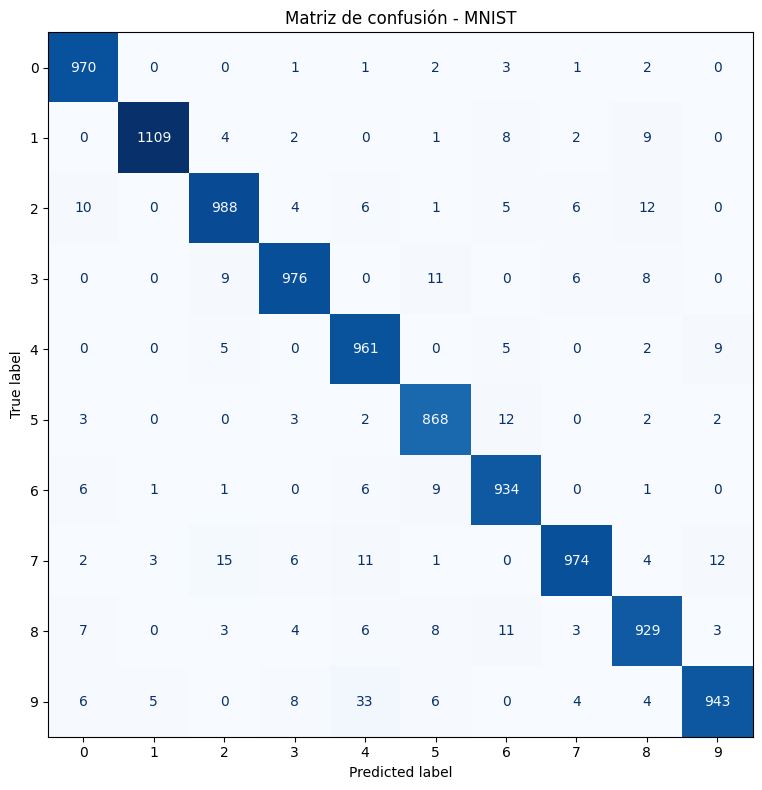

In [ ]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Matriz de confusión - MNIST")
plt.tight_layout(); plt.show()
pd.DataFrame(cm, index=[f"Real_{i}" for i in range(10)], columns=[f"Pred_{i}" for i in range(10)]).to_csv(OUTPUT_DIR / "matriz_confusion.csv")

## 6. Encontrar la confusión más frecuente y visualizar un error real

Confusión más frecuente: real 9 predicho como 4 (33 veces)


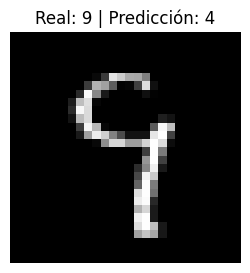

Índice del ejemplo en Test: 1192


In [ ]:
cm_errores = cm.copy()
np.fill_diagonal(cm_errores, 0)
real_confundido, predicho_como = np.unravel_index(np.argmax(cm_errores), cm_errores.shape)
cantidad = int(cm_errores[real_confundido, predicho_como])
print(f"Confusión más frecuente: real {real_confundido} predicho como {predicho_como} ({cantidad} veces)")

indices = np.where((y_test == real_confundido) & (y_pred == predicho_como))[0]
if len(indices) > 0:
    idx = int(indices[0])
    plt.figure(figsize=(3, 3))
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(f"Real: {y_test[idx]} | Predicción: {y_pred[idx]}")
    plt.axis("off"); plt.show()
    print("Índice del ejemplo en Test:", idx)
else:
    print("No se encontró un ejemplo para este par de clases; revisar la matriz.")

with open(OUTPUT_DIR / "confusion_mas_frecuente.txt", "w", encoding="utf-8") as f:
    f.write(f"Real {real_confundido} predicho como {predicho_como}: {cantidad} veces.\n")
    if len(indices) > 0: f.write(f"Índice de ejemplo en Test: {int(indices[0])}\n")

## 7. Elegir una clase débil para analizar

In [ ]:
reporte_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
tabla_clases = pd.DataFrame([
    {"digito": int(k), "precision": v["precision"], "recall": v["recall"], "f1": v["f1-score"], "support": v["support"]}
    for k, v in reporte_dict.items() if k.isdigit()
])
display(tabla_clases.sort_values("f1").head(3))
tabla_clases.to_csv(OUTPUT_DIR / "metricas_por_clase.csv", index=False)
print("Compara la clase con menor F1 frente al F1 macro e inspecciona sus errores en la matriz.")

,digito,precision,recall,f1,support
9,9,0.973168,0.934589,0.953488,1009.0
8,8,0.954779,0.953799,0.954289,974.0
4,4,0.936647,0.978615,0.957171,982.0


Compara la clase con menor F1 frente al F1 macro e inspecciona sus errores en la matriz.


## 8. Análisis requerido para el documento

- Reporta las cuatro métricas con cuatro decimales.
- Explica la diferencia entre Accuracy y las métricas macro.
- Identifica un dígito cuyo Precision, Recall o F1 esté por debajo del promedio y ofrece una interpretación basada en el reporte.
- Interpreta la diagonal de la matriz como aciertos y los valores fuera de la diagonal como errores.
- Nombra el par de dígitos que más se confundió y comenta el ejemplo visualizado.
- **No vuelvas a ajustar el modelo tomando decisiones a partir de Test.** El test debe quedar como evaluación final.